# 2. Network models

PyPSA-GB can represent the GB transmission network at four levels of detail. This tutorial solves the week of
[tutorial 1](1-first-run-2020.ipynb), 10 to 16 February 2020, on all four and compares them: what each network looks
like, what it changes in the results, and how clustering builds a network of any size from the full one.

| `network_model` | Size | Built from | Good for |
|---|---|---|---|
| `Zonal` | 17 zones | NESO's zonal model | fast national studies |
| `Reduced` | 32 buses | a published reduced GB network | quick runs and teaching |
| `ETYS` + clustering | about 300 buses (GSP regions) | the full network, merged region by region | a middle ground |
| `ETYS` | about 2,000 buses | NESO's Electricity Ten Year Statement | constraint and boundary studies |

The model description covers each network ([topology](../model/network/topology.md),
[clustering](../model/network/clustering.md)).

## Run it

The four scenarios differ only in their network (`config/studies/tutorials/scenarios.yaml`); the clustered one adds
`network: {clustering: gsp_spatial}`. Run them together:

```bash
snakemake -j 4 --config scenario=Tutorial_2020_zonal,Tutorial_2020_reduced,Tutorial_2020_clustered,Tutorial_2020_etys
```

The Zonal and Reduced runs take minutes. The clustered run takes 10 to 20 minutes, and the full ETYS run 30 to 60
minutes with about 16 GB of memory; skip it on a small machine, and the notebook leaves it out.

In [1]:
from pathlib import Path
import logging
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import pypsa

logging.getLogger("pypsa").setLevel(logging.ERROR)  # keep the notebook output short
warnings.filterwarnings("ignore", message=".*GDAL.*")
warnings.filterwarnings("ignore", message=".*gdalvrt.*")

# Work from the repository root, wherever Jupyter was started.
ROOT = Path.cwd()
while not (ROOT / "Snakefile").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)

# Technology groups for charts: each PyPSA-GB carrier belongs to one group.
GROUPS = {
    "Nuclear": ["nuclear"],
    "Coal": ["coal"],
    "Gas": ["CCGT", "OCGT", "gas_engine", "CHP", "CCS Gas"],
    "Oil": ["oil"],
    "Bioenergy": ["biomass", "CCS Biomass", "biogas", "landfill_gas", "sewage_gas", "waste_to_energy",
                  "advanced_biofuel", "geothermal"],
    "Hydro": ["large_hydro", "small_hydro"],
    "Marine": ["marine", "tidal_stream", "shoreline_wave", "tidal_lagoon"],
    "Onshore wind": ["wind_onshore", "embedded_wind"],
    "Offshore wind": ["wind_offshore", "floating_wind"],
    "Solar": ["solar_pv", "embedded_solar"],
}
GROUP_OF = {carrier: group for group, carriers in GROUPS.items() for carrier in carriers}
COLOURS = {
    "Nuclear": "#6250d6", "Coal": "#4b4b4b", "Gas": "#eb6834", "Oil": "#9b6a4f", "Bioenergy": "#008300",
    "Hydro": "#5fa8d3", "Marine": "#1f9e9e", "Onshore wind": "#1baf7a", "Offshore wind": "#2a78d6",
    "Solar": "#eda100", "Hydrogen": "#e34948", "Storage": "#e87ba4", "Imports": "#9aa5a0",
}
# Consumer flexibility (EVs, heat, demand response) is built from storage units but counts as demand.
CONSUMER_FLEX = {"EV_smart_charging", "V2G_fleet", "HP_flexibility", "DH_flexibility", "SH_flexibility",
                 "IC_DSR", "residential_DSR", "DACCS"}

plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e9e7", "legend.frameon": False, "font.size": 10})


def load(path):
    """Open a solved network, or say how to make it."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} does not exist yet: run the scenario first (see 'Run it' above).")
    return pypsa.Network(path)


def series(n, component, attribute, names):
    """A time series for each named component; a component without one takes its static value (or zero)."""
    table = getattr(n, f"{component}_t")[attribute]
    static = getattr(n, component).get(attribute, pd.Series(0.0, index=getattr(n, component).index))
    out = table.reindex(columns=names)
    for name in out.columns[out.isna().all()]:
        out[name] = float(static.get(name, 0.0)) if attribute in ("p_set", "p_max_pu") else 0.0
    return out.fillna(0.0)


def link_output(n, names):
    """Power each link delivers at its bus1 end (MW): p0 times efficiency, so it works whether or not p1 was saved."""
    return series(n, "links", "p0", names) * n.links.efficiency.reindex(names).values


def gb_buses(n):
    """GB electricity buses (the hydrogen bus is left out)."""
    return n.buses.index[(n.buses.country == "GB") & (n.buses.carrier == "AC")]


def generation_by_group(n):
    """GB generation by technology group (MW per snapshot); hydrogen turbines are their own group."""
    gens = n.generators[n.generators.bus.isin(gb_buses(n)) & n.generators.carrier.isin(GROUP_OF)]
    out = series(n, "generators", "p", gens.index).T.groupby(gens.carrier.map(GROUP_OF)).sum().T
    turbines = n.links.index[n.links.carrier == "H2_turbine"]
    if len(turbines):
        out["Hydrogen"] = link_output(n, turbines).sum(axis=1)  # output at the electricity end
    return out[[g for g in COLOURS if g in out and out[g].abs().sum() > 0]]


def interconnectors(n):
    cc = n.links.get("counterparty_country", pd.Series("", index=n.links.index)).fillna("").astype(str)
    return n.links[(n.links.carrier == "DC") & ~cc.isin(["", "nan", "None"])]


def net_imports(n):
    """Power the interconnectors deliver into GB (MW; negative = export)."""
    ic = interconnectors(n)
    gb = set(gb_buses(n))
    flows = {}
    for name, link in ic.iterrows():
        # p0 and p1 are withdrawals at bus0 and bus1; the GB end receives minus its withdrawal.
        # Power into GB: at bus0 it is minus the flow out of bus0; at bus1 it is the link's output there.
        flows[name] = (-series(n, "links", "p0", [name])[name] if link.bus0 in gb
                       else link_output(n, [name])[name])
    return pd.DataFrame(flows, index=n.snapshots).sum(axis=1)


def grid_storage(n):
    """Net output of grid storage (MW; positive = discharging). Consumer flexibility is left out."""
    units = n.storage_units.index[~n.storage_units.carrier.isin(CONSUMER_FLEX)]
    return series(n, "storage_units", "p", units).sum(axis=1)


def gb_demand(n):
    """GB electricity demand (MW): loads, the net draw of consumer flexibility, and electrolysis."""
    loads = n.loads.index[n.loads.bus.isin(gb_buses(n))]
    demand = series(n, "loads", "p_set", loads).sum(axis=1)
    flex = n.storage_units.index[n.storage_units.carrier.isin(CONSUMER_FLEX)]
    if len(flex):
        demand = demand - series(n, "storage_units", "p", flex).sum(axis=1)
    electrolysers = n.links.index[n.links.carrier == "electrolysis"]
    if len(electrolysers):
        demand = demand + series(n, "links", "p0", electrolysers).sum(axis=1)
    return demand


def day_axis(ax):
    """Label a time axis by day: Mon 10 Feb."""
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))


def stack_plot(ax, supply, demand=None, title=None):
    """Stacked supply (GW) by group, positive above zero and negative (charging, exports) below."""
    gw = supply / 1e3
    pos, neg = gw.clip(lower=0), gw.clip(upper=0)
    ax.stackplot(gw.index, pos.T.values, colors=[COLOURS[c] for c in gw.columns], labels=gw.columns, lw=0)
    ax.stackplot(gw.index, neg.T.values, colors=[COLOURS[c] for c in gw.columns], lw=0)
    if demand is not None:
        ax.plot(demand.index, demand / 1e3, color="black", lw=1.4, label="Demand")
    ax.axhline(0, color="#555", lw=0.6)
    ax.set_ylabel("GW")
    day_axis(ax)
    if title:
        ax.set_title(title, loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


import geopandas as gpd
from matplotlib.collections import LineCollection

GB_OUTLINE = gpd.read_file("data/network/GSP/GSP_regions_27700_20250109.geojson").to_crs(27700).dissolve()


def network_map(ax, n, line_values=None, cmap="viridis", vmin=0, vmax=1, bus_size=6, title=None):
    """GB buses and AC lines on British National Grid coordinates (metres); lines coloured by line_values."""
    GB_OUTLINE.plot(ax=ax, color="#eef3f0", edgecolor="#c9d6cf", lw=0.4)
    buses = n.buses.loc[gb_buses(n)]
    lines = n.lines[n.lines.bus0.isin(buses.index) & n.lines.bus1.isin(buses.index)]
    segments = [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(lines.bus0, lines.bus1)]
    internal = n.links[n.links.carrier.isin(["DC", "AC"]) & n.links.bus0.isin(buses.index)
                       & n.links.bus1.isin(buses.index)]
    ax.add_collection(LineCollection(
        [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(internal.bus0, internal.bus1)],
        colors="#7a8f86", linewidths=0.9, linestyles="dashed"))  # links inside GB (HVDC; zonal transport links)
    if line_values is None:
        collection = LineCollection(segments, colors="#7a8f86", linewidths=0.8)
    else:
        collection = LineCollection(segments, array=line_values.reindex(lines.index).values, cmap=cmap,
                                    linewidths=1.6, norm=plt.Normalize(vmin, vmax))
    ax.add_collection(collection)
    ax.scatter(buses.x, buses.y, s=bus_size, color="#2f4f43", zorder=3)
    ax.set_xlim(-20_000, 680_000)
    ax.set_ylim(-10_000, 1_225_000)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if title:
        ax.set_title(title, loc="left")
    return collection


MODELS = {
    "Zonal": "Tutorial_2020_zonal",
    "Reduced": "Tutorial_2020_reduced",
    "ETYS, clustered": "Tutorial_2020_clustered",
    "ETYS, full": "Tutorial_2020_etys",
}
networks = {}
for label, scenario in MODELS.items():
    path = Path(f"resources/network/{scenario}_solved.nc")
    if path.exists():
        networks[label] = pypsa.Network(path)
    else:
        print(f"{label}: not solved yet (snakemake -j 4 --config scenario={scenario})")
print("Loaded:", ", ".join(networks))

Loaded: Zonal, Reduced, ETYS, clustered, ETYS, full


## What each network looks like

Buses are nodes where generation and demand connect; lines carry AC power between them, and dashed lines are links:
HVDC links inside GB, and in the Zonal model the transport links between zones. Every network covers the same fleet and the same demand; what differs is how finely they are placed and how
many circuits can limit the flow between them.

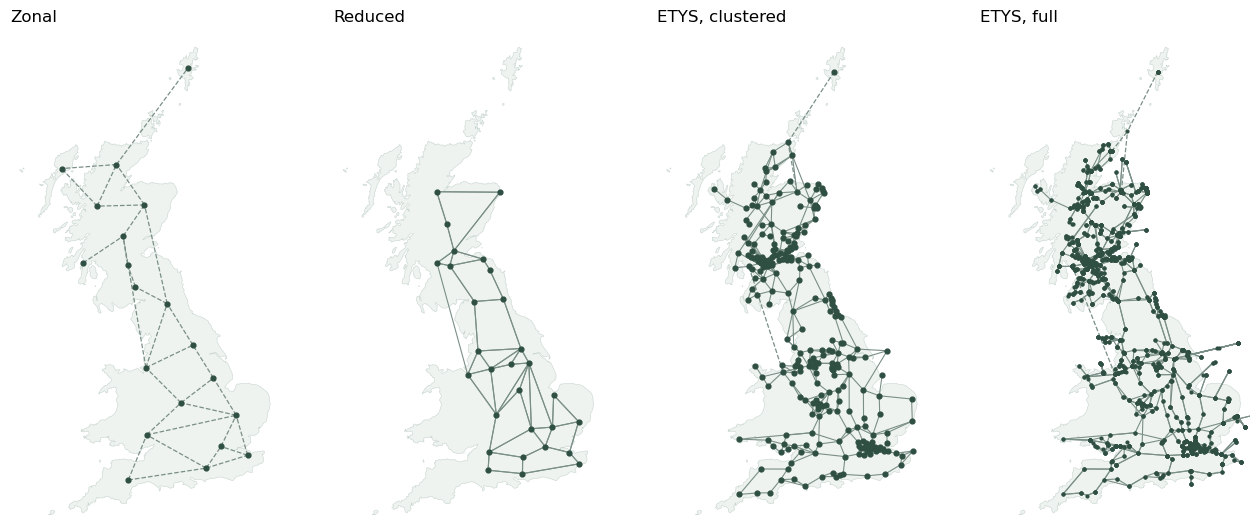

,Zonal,Reduced,"ETYS, clustered","ETYS, full"
GB buses,20,29,288,2123
AC lines,0,99,458,1656
transformers,0,0,0,1477
links inside GB,31,0,4,4
generators,2712,2750,5446,5446


In [2]:
def size(n):
    gb = gb_buses(n)
    return pd.Series({
        "GB buses": len(gb),
        "AC lines": int((n.lines.bus0.isin(gb) & n.lines.bus1.isin(gb)).sum()),
        "transformers": len(n.transformers),
        "links inside GB": int((n.links.carrier.isin(["DC", "AC"]) & n.links.bus0.isin(gb)
                                & n.links.bus1.isin(gb)).sum()),
        "generators": len(n.generators),
    })


fig, axes = plt.subplots(1, len(networks), figsize=(4 * len(networks), 6.5))
for ax, (label, n) in zip(list(axes) if len(networks) > 1 else [axes], networks.items()):
    network_map(ax, n, bus_size=4 if len(n.buses) > 500 else 12, title=label)
plt.show()

pd.DataFrame({label: size(n) for label, n in networks.items()})

The Zonal model has one bus per zone, joined by transport links that move power up to a limit without modelling
how it flows. The Reduced network has 29 GB buses and 99 lines: real power-flow physics on a coarse sketch of the
grid. The full ETYS network has about 2,100 buses, 1,650 lines and 1,480 transformers, every circuit NESO plans with.
Clustering to GSP regions keeps the full network's shape with about 290 buses.

## What changes in the results

The national picture barely moves: the same plant meets the same demand. What moves is everything the network decides:
how much wind can reach demand, how far prices differ between places, and so the cost.

In [3]:
def results(n):
    gb = gb_buses(n)
    wind = n.generators.index[n.generators.carrier.isin(["wind_onshore", "wind_offshore", "embedded_wind"])
                              & n.generators.bus.isin(gb)]
    available = (n.generators_t.p_max_pu.reindex(columns=wind, fill_value=1.0) * n.generators.p_nom[wind]).sum().sum()
    used = n.generators_t.p[wind].sum().sum()
    shed = n.generators.index[n.generators.carrier == "load_shedding"]
    prices = n.buses_t.marginal_price[gb]
    spread = prices.max(axis=1) - prices.min(axis=1)
    nuclear = n.generators.index[n.generators.carrier == "nuclear"]
    gas = n.generators.index[n.generators.carrier.isin(GROUPS["Gas"]) & n.generators.bus.isin(gb)]
    return pd.Series({
        "wind curtailed, %": 100 * (1 - used / available),
        "nuclear, GWh": n.generators_t.p[nuclear].sum().sum() / 1e3,
        "gas, GWh": n.generators_t.p[gas].sum().sum() / 1e3,
        "mean bus price, GBP/MWh": prices.mean().mean(),
        "hours with a price spread > GBP 1/MWh": int((spread > 1).sum()),
        "load shed, MWh": n.generators_t.p[shed].sum().sum(),
    })


pd.DataFrame({label: results(n) for label, n in networks.items()}).round(1)

,Zonal,Reduced,"ETYS, clustered","ETYS, full"
"wind curtailed, %",0.0,9.6,1.5,0.1
"nuclear, GWh",954.0,751.6,869.6,953.8
"gas, GWh",1082.8,1692.4,1246.5,1092.3
"mean bus price, GBP/MWh",37.6,25.1,27.3,37.3
hours with a price spread > GBP 1/MWh,0.0,158.0,134.0,168.0
"load shed, MWh",0.0,0.0,42.7,4.5


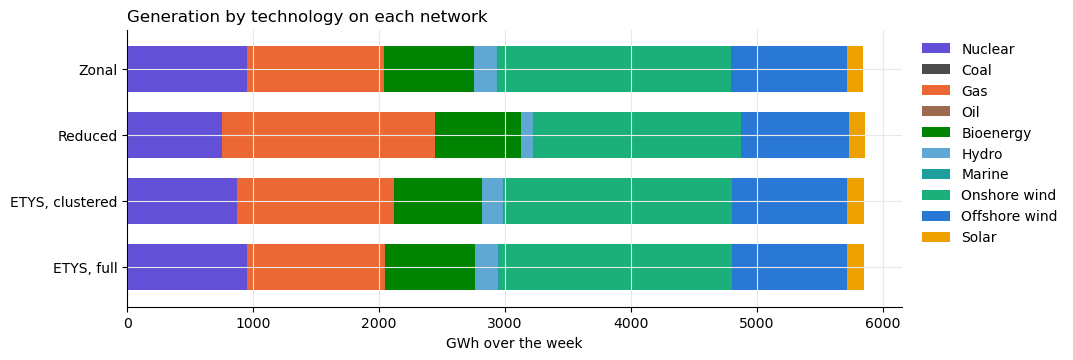

In [4]:
mix = pd.DataFrame({label: generation_by_group(n).sum() / 1e3 for label, n in networks.items()}).fillna(0)
ax = mix.T.plot.barh(stacked=True, color=[COLOURS[g] for g in mix.index], figsize=(10, 3.6), width=0.7)
ax.set_xlabel("GWh over the week")
ax.set_title("Generation by technology on each network", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.invert_yaxis()
plt.show()

More buses do not simply mean more constraints. Two things decide what a network does to the result:

- **How faithful the bottlenecks are.** The Reduced network carries northern Scotland on two 132 kV circuits and
  stands the Western HVDC link in as an AC line. Those become the week's bottleneck: about a tenth of the wind is
  curtailed and Scotland's nuclear stations are turned down. The full network has many parallel paths, so in this
  single solve almost nothing is curtailed, and nuclear matches the real week (958 GWh in ESPENI).
- **Which limits are applied.** A single solve respects each circuit's intact thermal rating at 275 and 400 kV. NESO
  also holds whole boundaries, such as Scotland to England, to secured limits that keep the system safe if a circuit
  trips; those are what bind in practice, and they are applied in the balancing stage of the two-stage market
  ([tutorial 5](5-two-stage-market-2030.ipynb)), not in a single solve (`network.transmission.outage_schedule`,
  off by default).

So the network you choose changes the answer. For national questions, any of them will do; for where and how much the
network constrains the system, use the full network with its boundary limits, as the studies do.

## Coordinates

Network buses carry British National Grid coordinates (OSGB36, EPSG:27700): `x` and `y` are metres east and north of
a point south-west of the Scilly Isles. Sites such as wind farms come with latitude and longitude (WGS84), so the
model converts between the two wherever it places a site on the network ([spatial mapping](../model/demand/placement.md)).

In [5]:
from pyproj import Transformer

n = networks.get("ETYS, full") or networks["Reduced"]
to_lonlat = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True)
sample = n.buses.loc[gb_buses(n)].head(5)[["x", "y"]].copy()
sample["lon"], sample["lat"] = to_lonlat.transform(sample.x.values, sample.y.values)
sample.round({"x": 0, "y": 0, "lon": 3, "lat": 3})

,x,y,lon,lat
name,,,,
ABBA1-,395693.0,806148.0,-2.073,57.146
ABNE1Q,320119.0,717097.0,-3.294,56.339
ABNE1R,320119.0,717097.0,-3.294,56.339
AIGA1Q,245905.0,841256.0,-4.569,57.435
ALNE1Q,264592.0,870979.0,-4.274,57.708


## Clustering

Clustering merges the full ETYS network's buses into fewer, larger ones: generation and demand are added up, parallel
lines combined, and the lines that cross between clusters kept as the limits. A preset names how to group the buses;
`gsp_spatial` groups them by Grid Supply Point region (`config/clustering.yaml`):

In [6]:
import yaml

presets = yaml.safe_load(Path("config/clustering.yaml").read_text())["presets"]
print(yaml.safe_dump({"gsp_spatial": presets["gsp_spatial"]}, sort_keys=False))

busmap = pd.read_csv("resources/network/Tutorial_2020_clustered_clustering_busmap.csv", index_col=0).iloc[:, 0]
per_cluster = busmap.value_counts()
print(f"{len(busmap)} ETYS buses into {per_cluster.size} clusters: "
      f"median {per_cluster.median():.0f} buses each, largest {per_cluster.max()}")

gsp_spatial:
  method: spatial
  boundaries_path: data/network/GSP/GSP_regions_27700_20250109.geojson
  cluster_column: GSPs
  bus_crs: EPSG:27700
  boundary_crs: EPSG:27700
  fallback: nearest_centroid
  convert_transformers_to_lines: true

2128 ETYS buses into 293 clusters: median 4 buses each, largest 57


The busmap (`resources/network/<scenario>_clustering_busmap.csv`) records which full-network bus went into which
cluster, so results on a clustered network can be traced back to places.

**Which to use?** Use the Reduced or Zonal network to learn the model and for quick national questions. Use the full
ETYS network when the answer depends on where the network binds: constraint costs, boundary flows, where wind is turned
down. That is why the [CP30 2030 study](../studies/cp30_2030.md) runs on it. A clustered network sits in between: the
regional shape of the full network at a fraction of the run time.

## Try it yourself

**Cluster by k-means instead.** Group the full network's buses into a chosen number of clusters by location:

```yaml
My_2020_kmeans_50:
  inherits: Tutorial_2020_reduced
  description: the tutorial week, ETYS clustered to 50 buses by k-means
  network_model: ETYS
  network:
    clustering: {method: kmeans, n_clusters: 50}
```

Try 20, 50 and 150 clusters, and watch the curtailment and price spread approach the full network's.

**A longer period.** Extend `solve_period` to a month on the Zonal network, which stays fast at any length.

Next: [tutorial 3](3-demand.ipynb) looks at demand in 2020, 2030 and 2040.